# Scalable learning with polynomial kernel approximation: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/kernel_approximation/plot_scalable_poly_kernels.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/kernel_approximation/plot_scalable_poly_kernels.html)).

**Scenario:** a `LinearSVC` on raw features is compared with `make_pipeline(PolynomialCountSketch(n_components=n,
degree=4), LinearSVC())` for several `n` and with an exact `SVC(C=500, kernel="poly", degree=4, coef0=0, gamma=1)`,
after `make_pipeline(MinMaxScaler(), Normalizer())` scaling.

**Adaptations:**
- **Data:** the example downloads Covtype (`fetch_covtype`); the network may be unavailable, so a bundled-free
  synthetic stand-in is used: `make_classification(n_samples=6000, n_features=54, n_informative=12,
  n_redundant=10, n_clusters_per_class=4, flip_y=0.02, random_state=0)` (54 features like Covtype, binary target
  like the example's "class 2 vs rest"). Sizes are reduced to `train_size=2000, test_size=4000` and
  `N_COMPONENTS = [250, 500, 1000]` (2000 dropped) to keep the native run short.
- `PolynomialCountSketch` gets `random_state=0` on both sides (the example leaves it `None`, i.e. a different
  sketch on every run); with a fixed seed the hashes, transforms and downstream LinearSVC become comparable.
  Moxie's documented adaptation for `None` is `fit_with_rng(X, context)`.
- The scaling pipeline `make_pipeline(MinMaxScaler(), Normalizer())` has no final predictor, which Moxie's typed
  `Pipeline` requires; Moxie applies the two Moxie preprocessors in sequence (what the pipeline does).
- Labels are typed `List[Float64]` for Moxie's `LinearSVC`/`SVC`.
- **Extension (not in the example):** section 3 puts each of the other four kernel maps (`RBFSampler`,
  `SkewedChi2Sampler`, `AdditiveChi2Sampler`, `Nystroem` with the same polynomial kernel) in the same
  `make_pipeline(map, LinearSVC())` on the scaled data, so the whole family is exercised in one scenario.
- Timings are printed, not compared.

**Determinism:** deterministic after fixing `random_state=0` for the sketches and maps; `LinearSVC` uses the
primal solver here (`dual="auto"`, more samples than features), which draws no random numbers.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("kernel_approximation/plot_scalable_poly_kernels")

## 1. scikit-learn (Python reference)

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_classification
from sklearn.kernel_approximation import PolynomialCountSketch
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer
from sklearn.svm import SVC, LinearSVC

# Stand-in for fetch_covtype (see adaptations).
X, y = make_classification(n_samples=6000, n_features=54, n_informative=12, n_redundant=10,
                           n_clusters_per_class=4, flip_y=0.02, random_state=0)
X_raw_train, X_raw_test, y_train, y_test = train_test_split(
    X, y, train_size=2_000, test_size=4_000, random_state=42
)
mm = make_pipeline(MinMaxScaler(), Normalizer())
X_train = mm.fit_transform(X_raw_train)
X_test = mm.transform(X_raw_test)

results = {}
lsvm = LinearSVC()
start = time.time()
lsvm.fit(X_train, y_train)
lsvm_time = time.time() - start
lsvm_score = 100 * lsvm.score(X_test, y_test)
results["LSVM"] = {"time": lsvm_time, "score": lsvm_score}
print(f"Linear SVM score on raw features: {lsvm_score:.2f}%")

n_runs = 1
N_COMPONENTS = [250, 500, 1000]
sk_ps_features = {}
for n_components in N_COMPONENTS:
    ps_lsvm_time = 0
    ps_lsvm_score = 0
    for _ in range(n_runs):
        pipeline = make_pipeline(
            PolynomialCountSketch(n_components=n_components, degree=4, random_state=0),
            LinearSVC(),
        )
        start = time.time()
        pipeline.fit(X_train, y_train)
        ps_lsvm_time += time.time() - start
        ps_lsvm_score += 100 * pipeline.score(X_test, y_test)
    ps_lsvm_time /= n_runs
    ps_lsvm_score /= n_runs
    results[f"LSVM + PS({n_components})"] = {"time": ps_lsvm_time, "score": ps_lsvm_score}
    print(f"Linear SVM score on {n_components} PolynomialCountSketch features: {ps_lsvm_score:.2f}%")
sk_index_hash = pipeline[0].indexHash_
sk_bit_hash = pipeline[0].bitHash_
sk_ps_test = pipeline[0].transform(X_test[:200])
sk_ps_decision = pipeline.decision_function(X_test)

ksvm = SVC(C=500.0, kernel="poly", degree=4, coef0=0, gamma=1.0)
start = time.time()
ksvm.fit(X_train, y_train)
ksvm_time = time.time() - start
ksvm_score = 100 * ksvm.score(X_test, y_test)
results["KSVM"] = {"time": ksvm_time, "score": ksvm_score}
print(f"Kernel-SVM score on raw features: {ksvm_score:.2f}%")
sk_scores = np.array([results["LSVM"]["score"]] + [results[f"LSVM + PS({n})"]["score"] for n in N_COMPONENTS]
                     + [results["KSVM"]["score"]])
nb.share(X_test=X_test, X_raw_train=X_raw_train, X_raw_test=X_raw_test,
         y_train=y_train.astype(np.float64), y_test=y_test.astype(np.float64))

Linear SVM score on raw features: 65.10%
Linear SVM score on 250 PolynomialCountSketch features: 70.95%


Linear SVM score on 500 PolynomialCountSketch features: 72.22%


Linear SVM score on 1000 PolynomialCountSketch features: 73.28%


Kernel-SVM score on raw features: 75.40%


In [3]:
%%mojo poly_sketch
from numojo import NDArray
from std.time import perf_counter_ns
from moxie.kernel_approximation import PolynomialCountSketch
from moxie.pipeline import make_pipeline
from moxie.preprocessing import MinMaxScaler, Normalizer
from moxie.svm import SVC, LinearSVC
from moxie_nb_io import load, save, save_floats, save_ints


def labels(y: NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(y.shape[0]):
        out.append(Float64(y.item(i)))
    return out^


def seconds(start: Int) -> Float64:
    return Float64(perf_counter_ns() - start) / 1e9


def main() raises:
    var y_train = labels(load("y_train"))
    var y_test = labels(load("y_test"))
    var scaler = MinMaxScaler()
    var normalizer = Normalizer()
    _ = scaler.fit(load("X_raw_train"))
    var X_train = normalizer.fit_transform(scaler.transform(load("X_raw_train")))
    var X_test = normalizer.transform(scaler.transform(load("X_raw_test")))
    save("X_train", X_train)

    var scores = List[Float64]()
    var lsvm = LinearSVC()
    var start = perf_counter_ns()
    _ = lsvm.fit(X_train, y_train)
    scores.append(100 * lsvm.score(X_test, y_test))
    print("Linear SVM score on raw features:", scores[0], "% (", seconds(start), "s )")

    for n_components in [250, 500, 1000]:
        var pipeline = make_pipeline(PolynomialCountSketch(n_components=n_components, degree=4, random_state=0), LinearSVC())
        start = perf_counter_ns()
        _ = pipeline.fit(X_train, y_train)
        var elapsed = seconds(start)
        scores.append(100 * pipeline.score(X_test, y_test))
        print("Linear SVM score on", n_components, "PolynomialCountSketch features:", scores[len(scores) - 1], "% (", elapsed, "s )")
        if n_components == 1000:
            var index_hash = List[Int]()
            var bit_hash = List[Int]()
            for k in range(pipeline.transformer.indexHash_.size):
                index_hash.append(Int(pipeline.transformer.indexHash_.unsafe_get(k)))
                bit_hash.append(Int(pipeline.transformer.bitHash_.unsafe_get(k)))
            save_ints("index_hash", index_hash)
            save_ints("bit_hash", bit_hash)
            save("ps_test", pipeline.transformer.transform(X_test))
            save("ps_decision", pipeline.estimator.decision_function(pipeline.transformer.transform(X_test)))

    var ksvm = SVC(C=500.0, kernel="poly", degree=4, coef0=0, gamma=1.0)
    start = perf_counter_ns()
    _ = ksvm.fit(X_train, y_train)
    scores.append(100 * ksvm.score(X_test, y_test))
    print("Kernel-SVM score on raw features:", scores[len(scores) - 1], "% (", seconds(start), "s )")
    save_floats("scores", scores)

Linear SVM score on raw features: 65.10000000000001 % ( 0.012014326 s )
Linear SVM score on 250 PolynomialCountSketch features: 70.95 % ( 0.23813311 s )
Linear SVM score on 500 PolynomialCountSketch features: 72.225 % ( 0.439294774 s )
Linear SVM score on 1000 PolynomialCountSketch features: 73.275 % ( 0.944293742 s )
Kernel-SVM score on raw features: 75.4 % ( 2.702381353 s )


## 2. Side by side and parity (example scope)

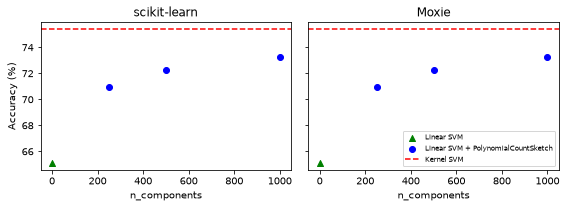

In [4]:
mx = nb.results["poly_sketch"]
names = ["LSVM"] + [f"LSVM + PS({n})" for n in N_COMPONENTS] + ["KSVM"]
moxie_nb.side_by_side(sklearn={n: [s] for n, s in zip(names, sk_scores)},
                      moxie={n: [s] for n, s in zip(names, mx["scores"])})
fig, axes = plt.subplots(1, 2, figsize=(8, 3), dpi=72, sharey=True)
for ax, title, s in [(axes[0], "scikit-learn", sk_scores), (axes[1], "Moxie", mx["scores"])]:
    ax.scatter([0], [s[0]], c="green", marker="^", label="Linear SVM")
    ax.scatter(N_COMPONENTS, s[1:-1], c="blue", label="Linear SVM + PolynomialCountSketch")
    ax.axhline(s[-1], c="red", ls="--", label="Kernel SVM")
    ax.set_title(title); ax.set_xlabel("n_components")
axes[0].set_ylabel("Accuracy (%)"); axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

nb.compare("MinMaxScaler + Normalizer training data", X_train, mx["X_train"], rtol=1e-12, atol=1e-15,
           reason="per-feature affine scaling and row L2 normalisation; a few ulp of rounding")
nb.compare("PolynomialCountSketch.indexHash_ (n=1000)", sk_index_hash.ravel(), mx["index_hash"], exact=True)
nb.compare("PolynomialCountSketch.bitHash_ (n=1000)", sk_bit_hash.ravel(), mx["bit_hash"], exact=True)
nb.compare("PolynomialCountSketch.transform(test) (n=1000)", pipeline[0].transform(X_test), mx["ps_test"], rtol=0, atol=1e-12,
           reason="FFT products of 4 count sketches of unit-norm rows: |values| <= ~1, mojo-linalg FFT vs pocketfft "
                  "rounding is O(degree * log2(M) * eps); see docs/kernel_approximation/polynomial/api.md")
nb.compare("PS(1000) + LinearSVC decision_function", sk_ps_decision, mx["ps_decision"], rtol=1e-4, atol=1e-4,
           reason="liblinear primal trust-region Newton stops at tol=1e-4 on features differing by ~1e-15")
nb.compare("accuracy (%): LSVM, PS(250/500/1000), KSVM", sk_scores, mx["scores"], rtol=0, atol=100 * 1.5 / len(y_test),
           reason="counts over 4000 test samples; allow one flipped near-boundary sample")
nb.note("fetch_covtype", "ADAPTED", "network download replaced by a 54-feature make_classification stand-in")
nb.note("PolynomialCountSketch(random_state=None)", "ADAPTED",
        "fixed random_state=0 on both sides; None needs fit_with_rng(X, context) in Moxie")

## 3. Extension: every kernel map before LinearSVC

Same scaled data, clipped at zero (`MinMaxScaler` fitted on the training half can map test values slightly below 0,
which the chi-squared maps reject in both libraries). Each map is used as `make_pipeline(map, LinearSVC())`.

In [5]:
from sklearn.kernel_approximation import AdditiveChi2Sampler, Nystroem, RBFSampler, SkewedChi2Sampler

maps = {
    "rbf": RBFSampler(gamma=1.0, n_components=300, random_state=0),
    "skewed": SkewedChi2Sampler(skewedness=1.0, n_components=300, random_state=0),
    "additive": AdditiveChi2Sampler(sample_steps=2),
    "nystroem": Nystroem(kernel="poly", degree=4, coef0=0, gamma=1.0, n_components=300, random_state=0),
}
X_pos_train, X_pos_test = np.clip(X_train, 0, None), np.clip(X_test, 0, None)
nb.share(X_pos_train=X_pos_train, X_pos_test=X_pos_test)
sk_map_scores, sk_map_features, sk_map_names = [], {}, []
for name, fmap in maps.items():
    pipe = make_pipeline(fmap, LinearSVC()).fit(X_pos_train, y_train)
    sk_map_scores.append(pipe.score(X_pos_test, y_test))
    sk_map_features[name] = pipe[0].transform(X_pos_test[:100])
    sk_map_names += list(pipe[0].get_feature_names_out())[:3]
sk_map_scores = np.array(sk_map_scores)
print(dict(zip(maps, np.round(sk_map_scores, 4))))

{'rbf': np.float64(0.684), 'skewed': np.float64(0.643), 'additive': np.float64(0.6822), 'nystroem': np.float64(0.7325)}


In [6]:
%%mojo all_maps
from numojo import NDArray, Shape
from moxie.kernel_approximation import RBFSampler, SkewedChi2Sampler, AdditiveChi2Sampler, Nystroem
from moxie.pipeline import make_pipeline
from moxie.svm import LinearSVC
from moxie_nb_io import load, save, save_floats, save_strings


def labels(y: NDArray[DType.float64]) raises -> List[Float64]:
    var out = List[Float64]()
    for i in range(y.shape[0]):
        out.append(Float64(y.item(i)))
    return out^


def head(x: NDArray[DType.float64], rows: Int) raises -> NDArray[DType.float64]:
    var out = NDArray[DType.float64](Shape(rows, x.shape[1]))
    for i in range(rows):
        for j in range(x.shape[1]):
            out.unsafe_set(i * x.shape[1] + j, x.unsafe_get(i * x.shape[1] + j))
    return out^


def main() raises:
    var X_train = load("X_pos_train")
    var X_test = load("X_pos_test")
    var y_train = labels(load("y_train"))
    var y_test = labels(load("y_test"))
    var X_head = head(X_test, 100)
    var scores = List[Float64]()
    var names = List[String]()

    var rbf = make_pipeline(RBFSampler(gamma=1.0, n_components=300, random_state=0), LinearSVC())
    _ = rbf.fit(X_train, y_train)
    scores.append(rbf.score(X_test, y_test))
    save("rbf", rbf.transformer.transform(X_head))
    var skewed = make_pipeline(SkewedChi2Sampler(skewedness=1.0, n_components=300, random_state=0), LinearSVC())
    _ = skewed.fit(X_train, y_train)
    scores.append(skewed.score(X_test, y_test))
    save("skewed", skewed.transformer.transform(X_head))
    var additive = make_pipeline(AdditiveChi2Sampler(sample_steps=2), LinearSVC())
    _ = additive.fit(X_train, y_train)
    scores.append(additive.score(X_test, y_test))
    save("additive", additive.transformer.transform(X_head))
    var nystroem = make_pipeline(Nystroem("poly", degree=4.0, coef0=0.0, gamma=1.0, n_components=300, random_state=0), LinearSVC())
    _ = nystroem.fit(X_train, y_train)
    scores.append(nystroem.score(X_test, y_test))
    save("nystroem", nystroem.transformer.transform(X_head))
    for group in [rbf.transformer.get_feature_names_out(), skewed.transformer.get_feature_names_out(),
                  additive.transformer.get_feature_names_out(), nystroem.transformer.get_feature_names_out()]:
        for k in range(3):
            names.append(group[k])
    save_floats("scores", scores)
    save_strings("names", names)

In [7]:
allm = nb.results["all_maps"]
moxie_nb.side_by_side(sklearn={k: [v] for k, v in zip(maps, sk_map_scores)},
                      moxie={k: [v] for k, v in zip(maps, allm["scores"])})
nb.compare("RBFSampler transform (300 comps)", sk_map_features["rbf"], allm["rbf"], rtol=0, atol=1e-12,
           reason="same draws; 54-term dot product summation order differs before cos, output scale 0.08")
nb.compare("SkewedChi2Sampler transform (300 comps)", sk_map_features["skewed"], allm["skewed"], rtol=0, atol=1e-11,
           reason="log(x + 1) in [0, 0.7] times heavy-tailed sech-distributed weights (|w| up to ~5) gives phases "
                  "up to a few hundred; a few ulp of phase error stays far below 1e-11 after the 0.08 scale")
nb.compare("AdditiveChi2Sampler transform", sk_map_features["additive"], allm["additive"], rtol=1e-12, atol=1e-15,
           reason="elementwise sqrt/log/cos/sin via platform libm on both sides")
nb.compare("Nystroem(poly, degree 4) transform (300 comps)", sk_map_features["nystroem"], allm["nystroem"], rtol=1e-5, atol=1e-6,
           reason="K^-1/2 of a 300x300 degree-4 polynomial Gram, possibly rank deficient (54 features): Jacobi SVD vs "
                  "gesdd agree only up to rotations inside clipped subspaces; see nystroem/api.md")
nb.compare("pipeline accuracy: rbf, skewed, additive, nystroem", sk_map_scores, allm["scores"], rtol=0, atol=1.5 / len(y_test),
           reason="counts over 4000 test samples; allow one flipped near-boundary sample")
nb.compare("get_feature_names_out (first 3 per map)", sk_map_names, list(allm["names"]), exact=True)
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
MinMaxScaler + Normalizer training data,PASS,"(2000, 54)","(2000, 54)",1.11e-16,6.57e-16,"rtol=1e-12, atol=1e-15",,per-feature affine scaling and row L2 normalisation; a few ulp of rounding
PolynomialCountSketch.indexHash_ (n=1000),PASS,"(216,)","(216,)",,,exact,0 mismatches,
PolynomialCountSketch.bitHash_ (n=1000),PASS,"(216,)","(216,)",,,exact,0 mismatches,
PolynomialCountSketch.transform(test) (n=1000),PASS,"(4000, 1000)","(4000, 1000)",3.61e-16,2.89e-09,"rtol=0, atol=1e-12",,"FFT products of 4 count sketches of unit-norm rows: |values| <= ~1, mojo-linalg FFT vs pocketfft rounding is O(degree * log2(M) * eps); see docs/kernel_approximation/polynomial/api.md"
PS(1000) + LinearSVC decision_function,PASS,"(4000,)","(4000,)",8.06e-12,5.15e-09,"rtol=0.0001, atol=0.0001",,liblinear primal trust-region Newton stops at tol=1e-4 on features differing by ~1e-15
"accuracy (%): LSVM, PS(250/500/1000), KSVM",PASS,"(5,)","(5,)",0,0,"rtol=0, atol=0.0375",,counts over 4000 test samples; allow one flipped near-boundary sample
fetch_covtype,ADAPTED,,,,,,network download replaced by a 54-feature make_classification stand-in,
PolynomialCountSketch(random_state=None),ADAPTED,,,,,,"fixed random_state=0 on both sides; None needs fit_with_rng(X, context) in Moxie",
RBFSampler transform (300 comps),PASS,"(100, 300)","(100, 300)",1.46e-16,2.13e-12,"rtol=0, atol=1e-12",,"same draws; 54-term dot product summation order differs before cos, output scale 0.08"
SkewedChi2Sampler transform (300 comps),PASS,"(100, 300)","(100, 300)",7.29e-17,5.56e-12,"rtol=0, atol=1e-11",,"log(x + 1) in [0, 0.7] times heavy-tailed sech-distributed weights (|w| up to ~5) gives phases up to a few hundred; a few ulp of phase error stays far below 1e-11 after the 0.08 scale"
